# 06 · Player attacking: goals & assists

How many goals and assists should we expect from a player in a given fixture?

## The idea: a player's *share* of his team's chances
`expected goals for the player = his share of team xG × team's expected goals in this fixture × fraction of the match he plays`

- **Share** = his xG ÷ his team's xG *while he was on the pitch*, over recent matches, shrunk toward the average share for
  his position (so a player with 2 lucky shots in 40 minutes isn't treated as Haaland).
- **Team's expected goals** come from notebook 05: they already include **opponent strength and home/away**. So a
  striker's expectation rises against weak defences and at home without any player-specific home/away split
  (which notebook 05 showed is noise).
- Assists work the same way with **xA**.
- A match's goals (or assists) are treated as a **Poisson** count: P(at least one) = 1 − e^(−λ).

To judge this component *on its own*, we evaluate it **given the minutes each player actually played**. Uncertainty
about minutes comes from the minutes model and gets combined in notebook 08.

Code: [`fpl_engine/models/attacking.py`](../fpl_engine/models/attacking.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db
from fpl_engine.features import load_base, build_features
from fpl_engine.models import team_strength as ts, attacking as at
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
with db.connect() as conn:
    base = load_base(conn)
    matches = ts.load_matches(conn)
    names = pd.read_sql('SELECT player_id, web_name FROM core.players', conn).set_index('player_id').web_name
ctx = at.team_context(matches)                 # team xG history + pre-deadline team predictions (notebook 05 model)
b = at.add_team_columns(base, ctx)
f = build_features(b)
f = f.merge(b[['player_id', 'fixture_id', 'team_lam_for', 'team_xg_on', 'xg', 'xa']].rename(
    columns={'team_xg_on': 'team_xg_on_actual', 'xg': 'y_xg_raw', 'xa': 'y_xa_raw'}), on=['player_id', 'fixture_id'])
train = f[f.season.isin(['2022-23', '2023-24'])]
test = f[(f.season >= '2024-25') & (f.y_minutes > 0) & f.team_lam_for.notna()]
print(f'train {len(train):,} rows (2022-23, 2023-24) · evaluate {len(test):,} appearances (2024-25 →)')

train 56,230 rows (2022-23, 2023-24) · evaluate 26,423 appearances (2024-25 →)


## 1 · Does it beat simpler approaches?
- **goals/90 (raw)**: a player's actual goals per 90 over his last 10 matches. The naive "form" approach.
- **xG/90 & xA/90 (shrunk)**: underlying rates with shrinkage, but no team or opponent adjustment.
- **share model**: the approach above.

Metrics: **log-likelihood** (higher = better; heavily punishes saying "almost no chance" when he scores) and
**Brier** of P(at least one) (lower = better).

In [2]:
for d in (train, test):
    m90 = d.mins90_sum_l10.where(d.mins90_sum_l10 > 0)
    d['goals90_raw'], d['assists90_raw'] = d.goals_sum_l10 / m90, d.assists_sum_l10 / m90
models = {'goals/90 last 10 (raw)': at.RatePerNinety('goals90_raw', 'assists90_raw', 'raw'),
          'xG/90 & xA/90 (shrunk)': at.RatePerNinety('xg90_ewm5', 'xa90_ewm5', 'xg90'),
          'share model (team & opponent aware)': at.AttackingModel()}
res = {}
for name, mdl in models.items():
    mdl.fit(train); res[name] = at.evaluate(test, mdl.predict(test))
pd.DataFrame(res).T.round(4)

,goals log-lik,goal Brier,assists log-lik,assist Brier,rows
goals/90 last 10 (raw),-0.5739,0.0756,-0.6436,0.0771,26423.0
xG/90 & xA/90 (shrunk),-0.2752,0.0680,-0.2803,0.0693,26423.0
share model (team & opponent aware),-0.2661,0.0672,-0.2699,0.0682,26423.0


- Raw goal form is **far worse**: a player with no goals in 10 games gets an expected rate of zero, then scores.
  Shrinkage and xG fix that.
- The **share model is best** on both goals and assists: adding team strength and the opponent helps.

## 2 · How much shrinkage, and which window?

In [3]:
grid = {}
for w in ['l10', 'ewm5', 'ewm10', 'ewm20']:
    for k in [1, 3, 10, 30]:
        mdl = at.AttackingModel(at.AttackingConfig(window=w, k_share=k)); mdl.fit(train)
        grid[(w, k)] = at.evaluate(test, mdl.predict(test))['goals log-lik']
g = pd.Series(grid).unstack(); g.index.name = 'window'; g.columns.name = 'k (team-xG units)'
g.round(4)

k (team-xG units),1,3,10,30
window,,,,
ewm10,-0.2669,-0.2656,-0.2653,-0.2668
ewm20,-0.2678,-0.2664,-0.2655,-0.2661
ewm5,-0.2673,-0.2658,-0.2661,-0.2681
l10,-0.2701,-0.2674,-0.2664,-0.2678


A recent-weighted window (`ewm5`: each match's weight halves every 5 fixtures) with fairly strong shrinkage
(**k ≈ 10**, about six matches' worth of team xG) works best. That's now the default.

## 3 · Is finishing a skill?
Some players score more than their xG. Is that **repeatable** (worth modelling) or **luck**? For players with 1,500+
minutes and 3+ xG in consecutive seasons:

131 player-season pairs · correlation of goals/xG ratio year to year: -0.014


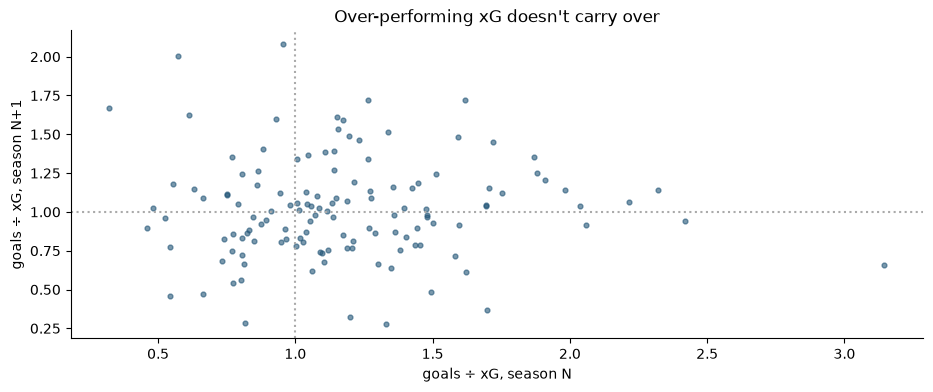

In [4]:
bb = base[(base.minutes > 0) & (base.season >= '2022-23')]
s = bb.groupby(['player_id', 'season']).agg(goals=('goals', 'sum'), xg=('xg', 'sum'), mins=('minutes', 'sum')).reset_index()
s = s[(s.mins >= 1500) & (s.xg >= 3)].assign(ratio=lambda x: x.goals / x.xg)
s['next'] = s.season.map({'2022-23': '2023-24', '2023-24': '2024-25', '2024-25': '2025-26'})
j = s.merge(s[['player_id', 'season', 'ratio']].rename(columns={'season': 'next', 'ratio': 'ratio_next'}), on=['player_id', 'next'])
print(f"{len(j)} player-season pairs · correlation of goals/xG ratio year to year: {j.ratio.corr(j.ratio_next):.3f}")
ax = plt.gca(); ax.scatter(j.ratio, j.ratio_next, s=12, alpha=.6, color='#257'); ax.axhline(1, color='#aaa', ls=':'); ax.axvline(1, color='#aaa', ls=':')
ax.set_xlabel('goals ÷ xG, season N'); ax.set_ylabel('goals ÷ xG, season N+1'); ax.set_title('Over-performing xG doesn\'t carry over'); plt.show()

**Finishing above xG doesn't persist** (correlation ≈ 0): a player who beat his xG last season is no more likely to
do so this season. So we **don't** give players personal finishing multipliers. xG share is the signal and the rest is
luck. (Elite finishers do exist, but their edge is too small to detect reliably at FPL sample sizes.)

## 4 · A data shift, again, and calibration

The model learns a **calibration multiplier** per position: actual goals (or FPL assists) ÷ the model's raw expectation.
It turns "expected" stats into how FPL actually awards points. But the relationship between FPL's xG and real goals
**isn't stable**:

In [5]:
p_ = f[(f.y_minutes > 0) & (f.season >= '2022-23')]
s_ = p_.groupby('season').agg(goals=('y_goals', 'sum'), xg=('y_xg_raw', 'sum'), assists=('y_assists', 'sum'), xa=('y_xa_raw', 'sum'))
pd.DataFrame({'goals ÷ FPL xG': s_.goals / s_.xg, 'FPL assists ÷ xA': s_.assists / s_.xa}).round(3)

,goals ÷ FPL xG,FPL assists ÷ xA
season,,
2022-23,1.419,2.111
2023-24,0.998,1.424
2024-25,0.982,1.374
2025-26,0.941,1.379
2026-27,0.874,1.360


In **2022-23** (FPL's first season publishing xG) actual goals were 1.42× xG; since then about 1.0. And FPL awards
~1.4× more assists than xA predicts (2–3× for forwards: rebounds, penalties won, deflections). So the model calibrates on
the **most recent 365 days** of training data only, and in real use it's **retrained every 5 gameweeks**, so it keeps
tracking such shifts. Here it is in a proper rolling backtest:

In [6]:
keys = sorted(f.loc[f.season >= '2024-25', 'gw_key'].unique())
roll_model, out = at.AttackingModel(), []
for i, g in enumerate(keys):
    if i % 5 == 0:
        roll_model.fit(f[(f.gw_key < g) & (f.season >= '2022-23')])
    te = f[(f.gw_key == g) & (f.y_minutes > 0) & f.team_lam_for.notna()]
    out.append(pd.concat([te[['season', 'y_goals', 'y_assists']], roll_model.predict(te)], axis=1))
o = pd.concat(out)
print('rolling backtest:', {k: round(v, 4) for k, v in at.evaluate(o, o).items()})
o.groupby('season').apply(lambda d: pd.Series({'predicted ÷ actual goals': d.lam_goals.sum() / d.y_goals.sum(),
                                               'predicted ÷ actual assists': d.lam_assists.sum() / d.y_assists.sum()}),
                          include_groups=False).round(3)

rolling backtest: {'goals log-lik': -0.2656, 'goal Brier': 0.0671, 'assists log-lik': -0.2696, 'assist Brier': 0.0681, 'rows': 26423}


,predicted ÷ actual goals,predicted ÷ actual assists
season,,
2024-25,1.082,1.078
2025-26,1.002,0.977
2026-27,1.015,1.024


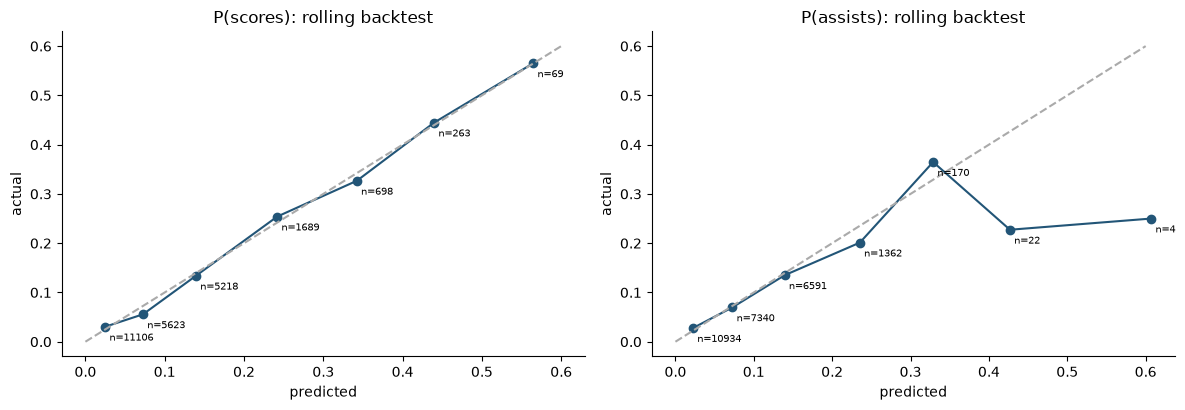

latest calibration multipliers (actual ÷ raw expectation, last 365 days):


,goals,assists
DEF,0.848,1.345
FWD,1.002,2.272
GKP,0.000,3.842
MID,0.994,1.352


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (col, y, title) in zip(axes, [('p_goal', o.y_goals > 0, 'P(scores)'), ('p_assist', o.y_assists > 0, 'P(assists)')]):
    d = pd.DataFrame({'p': o[col], 'y': y.astype(float)})
    cal = d.groupby(pd.cut(d.p, [0, .05, .1, .2, .3, .4, .5, 1]), observed=True).agg(pred=('p', 'mean'), actual=('y', 'mean'), n=('y', 'size'))
    ax.plot(cal.pred, cal.actual, marker='o', color='#257'); ax.plot([0, .6], [0, .6], '--', color='#aaa')
    for _, r in cal.iterrows(): ax.annotate(f"n={int(r.n)}", (r.pred, r.actual), fontsize=7, xytext=(3, -10), textcoords='offset points')
    ax.set_title(f'{title}: rolling backtest'); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.tight_layout(); plt.show()
best = roll_model
print('latest calibration multipliers (actual ÷ raw expectation, last 365 days):')
pd.DataFrame(best.calib).round(3)

## 5 · Who does the model rate? (one example gameweek)

In [8]:
gw = f[(f.season == '2025-26') & (f.gameweek == 20) & (f.y_minutes > 0) & f.team_lam_for.notna()].copy()
pp = best.predict(gw, minutes=pd.Series(90.0, index=gw.index))           # per 90 minutes, to compare like with like
gw = gw.assign(name=gw.player_id.map(names), share_xg=best.shares(gw).share_xg, **pp)
gw[['name', 'position', 'team_lam_for', 'share_xg', 'lam_goals', 'p_goal', 'lam_assists', 'p_assist', 'y_goals', 'y_assists']] \
    .sort_values('lam_goals', ascending=False).head(12).round(3).reset_index(drop=True)

,name,position,team_lam_for,share_xg,lam_goals,p_goal,lam_assists,p_assist,y_goals,y_assists
0,Welbeck,FWD,2.339,0.319,0.747,0.526,0.191,0.174,0.0,0.0
1,Haaland,FWD,2.052,0.327,0.672,0.489,0.181,0.166,0.0,0.0
2,Kostoulas,FWD,2.339,0.272,0.638,0.472,0.290,0.252,0.0,1.0
3,Watkins,FWD,1.514,0.353,0.535,0.415,0.136,0.128,1.0,0.0
4,Wissa,FWD,1.686,0.306,0.517,0.404,0.216,0.194,0.0,0.0
5,Calvert-Lewin,FWD,1.612,0.313,0.505,0.396,0.143,0.133,0.0,0.0
6,Nmecha,FWD,1.612,0.298,0.482,0.383,0.155,0.143,0.0,0.0
7,Woltemade,FWD,1.686,0.273,0.462,0.370,0.128,0.120,0.0,0.0
8,Richarlison,FWD,1.459,0.304,0.445,0.359,0.241,0.214,0.0,0.0
9,Piroe,FWD,1.612,0.260,0.420,0.343,0.168,0.155,0.0,0.0


(Per 90 minutes; in the full model these are multiplied by the minutes model's expected playing time.)
**Penalties** are included automatically: a penalty is about 0.76 xG, so regular takers have a higher xG share.

---
## ✅ Decisions (made with you, 2026-11-23)
1. **Share model adopted** for goals and assists: team- and opponent-aware, `ewm5` window, k = 10, calibrated on the
   latest 365 days, retrained every 5 gameweeks.
2. **No personal finishing multiplier:** finishing above xG doesn't persist.
3. **Penalty takers:** for live predictions, use FPL's penalty order to adjust for new or changed takers; as soon as
   someone actually takes penalties, his xG share picks it up automatically. (Implemented with the live prediction
   pipeline in notebook 08.)